In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [3]:
bookings = pd.read_csv("bookings.csv")
guests = pd.read_csv("guests.csv")
hotels = pd.read_csv("hotels.csv")
channels = pd.read_csv("channels.csv")
calendar = pd.read_csv("calendar.csv")

In [4]:
for name, df in {
    "Bookings": bookings,
    "Guests": guests,
    "Hotels": hotels,
    "Channels": channels,
    "Calendar": calendar
}.items():
    print(f"\n{name}")
    display(df.head())


Bookings


,booking_id,guest_id,hotel_id,channel_id,booking_date,stay_date,room_type,rate,status,rooms_booked,nights
0,B00001,G00005,H005,C05,2025-12-31,2026-03-20,Family Room,5662.0,Cancelled,1,1
1,B00002,G01152,H008,C03,2026-09-16,2026-10-02,Family Room,5359.0,Confirmed,1,1
2,B00003,G00571,H018,C01,2024-03-09,2024-05-21,Deluxe,4217.0,Confirmed,1,4
3,B00004,G01101,H006,C07,2026-05-16,2026-07-17,Family Room,4812.0,Confirmed,1,2
4,B00005,G01178,H013,C02,2024-12-27,2025-01-14,Standard,2364.0,Cancelled,1,1



Guests


,guest_id,guest_type,origin,repeat_status
0,G00001,Solo,Sri Lanka,New
1,G00002,Leisure,Canada,New
2,G00003,Business,Canada,New
3,G00004,Business,Australia,Repeat
4,G00005,Leisure,Singapore,New



Hotels


,hotel_id,hotel_name,city,property_type,capacity
0,H001,StayNest Chennai 01,Chennai,Budget,134
1,H002,StayNest Bengaluru 02,Bengaluru,Resort,131
2,H003,StayNest Hyderabad 03,Hyderabad,Boutique,67
3,H004,StayNest Kochi 04,Kochi,Budget,108
4,H005,StayNest Coimbatore 05,Coimbatore,Business,54



Channels


,channel_id,booking_channel,campaign
0,C01,Direct Website,Festive Offer
1,C02,Online Travel Agency,NaN
2,C03,Mobile App,Weekend Escape
3,C04,Corporate,NaN
4,C05,Travel Agent,Corporate Deal



Calendar


,date,weekend,holiday,season,event,event_name
0,2024-01-01,False,True,Winter,False,NaN
1,2024-01-02,False,False,Winter,False,NaN
2,2024-01-03,False,False,Winter,False,NaN
3,2024-01-04,False,False,Winter,False,NaN
4,2024-01-05,False,False,Winter,False,NaN


In [5]:
datasets = {
    "bookings": bookings,
    "guests": guests,
    "hotels": hotels,
    "channels": channels,
    "calendar": calendar
}

for name, df in datasets.items():
    print(f"\n--- {name.upper()} ---")
    print("Shape:", df.shape)
    print("\nData types:")
    print(df.dtypes)
    print("\nSummary:")
    display(df.describe(include="all").T)


--- BOOKINGS ---
Shape: (4020, 11)

Data types:
booking_id       object
guest_id         object
hotel_id         object
channel_id       object
booking_date     object
stay_date        object
room_type        object
rate            float64
status           object
rooms_booked      int64
nights            int64
dtype: object

Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
booking_id,4020,4000,B00595,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
guest_id,4020,1612,G01795,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hotel_id,4020,18,H001,251,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_id,4020,7,C01,610,NaN,NaN,NaN,NaN,NaN,NaN,NaN
booking_date,4020,1041,2026-03-05,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stay_date,4020,1079,2026-11-03,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
room_type,4020,20,Standard,1424,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rate,4020.0,NaN,NaN,NaN,4716.937065,3723.609437,1597.0,2975.0,4108.5,5806.25,128340.0
status,4020,2,Confirmed,3326,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rooms_booked,4020.0,NaN,NaN,NaN,1.160199,0.457943,1.0,1.0,1.0,1.0,3.0



--- GUESTS ---
Shape: (1800, 4)

Data types:
guest_id         object
guest_type       object
origin           object
repeat_status    object
dtype: object

Summary:


,count,unique,top,freq
guest_id,1800,1800,G01800,1
guest_type,1800,5,Leisure,615
origin,1735,10,Germany,194
repeat_status,1800,2,New,1271



--- HOTELS ---
Shape: (18, 5)

Data types:
hotel_id         object
hotel_name       object
city             object
property_type    object
capacity          int64
dtype: object

Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel_id,18,18,H001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hotel_name,18,18,StayNest Chennai 01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,18,6,Chennai,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
property_type,18,5,Budget,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
capacity,18.0,NaN,NaN,NaN,100.277778,32.29971,42.0,76.25,110.5,124.5,147.0



--- CHANNELS ---
Shape: (7, 3)

Data types:
channel_id         object
booking_channel    object
campaign           object
dtype: object

Summary:


,count,unique,top,freq
channel_id,7,7,C01,1
booking_channel,7,7,Direct Website,1
campaign,5,4,Corporate Deal,2



--- CALENDAR ---
Shape: (1096, 6)

Data types:
date          object
weekend         bool
holiday         bool
season        object
event           bool
event_name    object
dtype: object

Summary:


,count,unique,top,freq
date,1096,1096,2026-12-31,1
weekend,1096,2,False,784
holiday,1096,2,False,1084
season,1096,5,Monsoon,366
event,1096,2,False,991
event_name,105,1,Local Festival/Event,105


In [6]:
for name, df in datasets.items():
    print(name, ":", df.columns.tolist())

bookings : ['booking_id', 'guest_id', 'hotel_id', 'channel_id', 'booking_date', 'stay_date', 'room_type', 'rate', 'status', 'rooms_booked', 'nights']
guests : ['guest_id', 'guest_type', 'origin', 'repeat_status']
hotels : ['hotel_id', 'hotel_name', 'city', 'property_type', 'capacity']
channels : ['channel_id', 'booking_channel', 'campaign']
calendar : ['date', 'weekend', 'holiday', 'season', 'event', 'event_name']


In [7]:
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print(df.isnull().sum())
    print("Missing percentage:")
    print((df.isnull().mean() * 100).round(2))


BOOKINGS
booking_id      0
guest_id        0
hotel_id        0
channel_id      0
booking_date    0
stay_date       0
room_type       0
rate            0
status          0
rooms_booked    0
nights          0
dtype: int64
Missing percentage:
booking_id      0.0
guest_id        0.0
hotel_id        0.0
channel_id      0.0
booking_date    0.0
stay_date       0.0
room_type       0.0
rate            0.0
status          0.0
rooms_booked    0.0
nights          0.0
dtype: float64

GUESTS
guest_id          0
guest_type        0
origin           65
repeat_status     0
dtype: int64
Missing percentage:
guest_id         0.00
guest_type       0.00
origin           3.61
repeat_status    0.00
dtype: float64

HOTELS
hotel_id         0
hotel_name       0
city             0
property_type    0
capacity         0
dtype: int64
Missing percentage:
hotel_id         0.0
hotel_name       0.0
city             0.0
property_type    0.0
capacity         0.0
dtype: float64

CHANNELS
channel_id         0
booking_chann

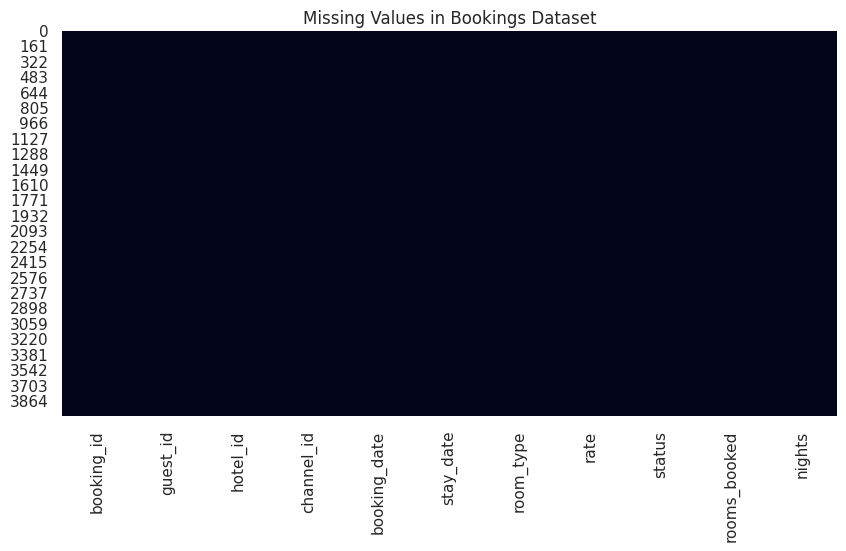

In [8]:
plt.figure(figsize=(10, 5))
sns.heatmap(bookings.isnull(), cbar=False)
plt.title("Missing Values in Bookings Dataset")
plt.show()

In [9]:
# Example: use only if the origin column exists
if "origin" in guests.columns:
    guests["origin"] = guests["origin"].fillna("Unknown")

In [10]:
for name, df in datasets.items():
    print(name, "duplicate rows:", df.duplicated().sum())

bookings duplicate rows: 20
guests duplicate rows: 0
hotels duplicate rows: 0
channels duplicate rows: 0
calendar duplicate rows: 0


In [11]:
bookings = bookings.drop_duplicates().copy()
guests = guests.drop_duplicates().copy()
hotels = hotels.drop_duplicates().copy()
channels = channels.drop_duplicates().copy()
calendar = calendar.drop_duplicates().copy()

In [12]:
# Change booking_id to your actual booking identifier
if "booking_id" in bookings.columns:
    print(
        bookings[bookings.duplicated("booking_id", keep=False)]
        .sort_values("booking_id")
    )

Empty DataFrame
Columns: [booking_id, guest_id, hotel_id, channel_id, booking_date, stay_date, room_type, rate, status, rooms_booked, nights]
Index: []


In [13]:
date_columns = ["booking_date", "stay_date"]

for col in date_columns:
    if col in bookings.columns:
        bookings[col] = pd.to_datetime(
            bookings[col], errors="coerce"
        )

In [14]:
for col in ["rate"]:
    if col in bookings.columns:
        bookings[col] = pd.to_numeric(
            bookings[col], errors="coerce"
        )

In [15]:
print(bookings.dtypes)

booking_id              object
guest_id                object
hotel_id                object
channel_id              object
booking_date    datetime64[ns]
stay_date       datetime64[ns]
room_type               object
rate                   float64
status                  object
rooms_booked             int64
nights                   int64
dtype: object


In [16]:
for col in ["room_type", "status"]:
    if col in bookings.columns:
        bookings[col] = (
            bookings[col]
            .astype("string")
            .str.strip()
            .str.lower()
            .str.replace(r"\s+", " ", regex=True)
        )

print(bookings["room_type"].value_counts(dropna=False))
print(bookings["status"].value_counts(dropna=False))

room_type
standard       1444
deluxe         1123
family room     685
suite           381
executive       367
Name: count, dtype: Int64
status
confirmed    3311
cancelled     689
Name: count, dtype: Int64


In [17]:
if {"booking_date", "stay_date"}.issubset(bookings.columns):
    print("Missing booking dates:",
          bookings["booking_date"].isna().sum())

    print("Missing stay dates:",
          bookings["stay_date"].isna().sum())

    invalid_dates = bookings[
        bookings["stay_date"] < bookings["booking_date"]
    ]

    print("Stay before booking:", len(invalid_dates))
    display(invalid_dates.head())

Missing booking dates: 0
Missing stay dates: 0
Stay before booking: 12


,booking_id,guest_id,hotel_id,channel_id,booking_date,stay_date,room_type,rate,status,rooms_booked,nights
531,B00532,G01799,H010,C04,2026-04-05,2026-04-03,standard,3047.0,cancelled,1,2
608,B00609,G00598,H008,C03,2024-12-12,2024-12-09,standard,2679.0,confirmed,1,1
1389,B01390,G01439,H013,C07,2024-12-19,2024-12-13,suite,7396.0,confirmed,1,5
1447,B01448,G00801,H013,C03,2025-12-17,2025-12-13,deluxe,4172.0,confirmed,2,1
1653,B01654,G00590,H005,C01,2025-05-19,2025-05-16,family room,5358.0,confirmed,1,3


count      4000.00000
mean       4716.23450
std        3730.03929
min        1597.00000
25%        2974.75000
50%        4106.00000
75%        5806.25000
max      128340.00000
Name: rate, dtype: float64


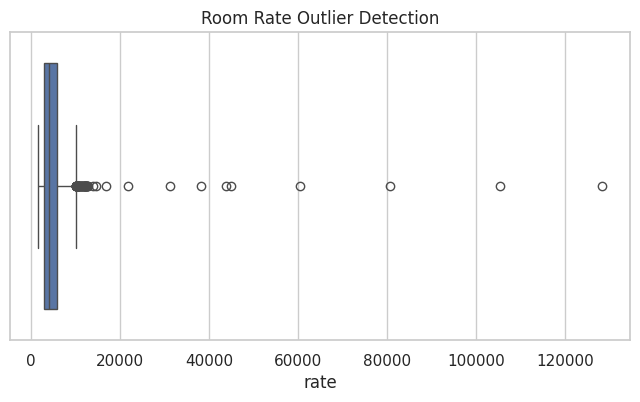

In [18]:
if "rate" in bookings.columns:
    print(bookings["rate"].describe())

    plt.figure(figsize=(8, 4))
    sns.boxplot(x=bookings["rate"])
    plt.title("Room Rate Outlier Detection")
    plt.show()

In [19]:
rate = bookings["rate"].dropna()

Q1 = rate.quantile(0.25)
Q3 = rate.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = bookings[
    (bookings["rate"] < lower) |
    (bookings["rate"] > upper)
]

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Potential outliers:", len(outliers))
display(outliers.head())

Lower limit: -1272.5
Upper limit: 10053.5
Potential outliers: 58


,booking_id,guest_id,hotel_id,channel_id,booking_date,stay_date,room_type,rate,status,rooms_booked,nights
69,B00070,G01015,H017,C04,2024-10-16,2024-11-13,suite,12874.0,confirmed,1,1
190,B00191,G01122,H017,C01,2025-12-17,2026-01-11,suite,10403.0,confirmed,2,4
284,B00285,G00063,H010,C07,2024-11-03,2024-12-31,suite,14632.0,confirmed,1,1
307,B00308,G01394,H010,C04,2026-09-30,2026-11-13,suite,10894.0,confirmed,1,3
413,B00414,G00336,H017,C06,2026-06-30,2026-10-11,family room,80736.0,confirmed,1,1


In [20]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.columns.tolist())


bookings
['booking_id', 'guest_id', 'hotel_id', 'channel_id', 'booking_date', 'stay_date', 'room_type', 'rate', 'status', 'rooms_booked', 'nights']

guests
['guest_id', 'guest_type', 'origin', 'repeat_status']

hotels
['hotel_id', 'hotel_name', 'city', 'property_type', 'capacity']

channels
['channel_id', 'booking_channel', 'campaign']

calendar
['date', 'weekend', 'holiday', 'season', 'event', 'event_name']


In [21]:
# Example merge — use only if these keys exist
merged = bookings.merge(
    guests, on="guest_id", how="left",
    validate="many_to_one"
)

merged = merged.merge(
    hotels, on="hotel_id", how="left",
    validate="many_to_one"
)

merged = merged.merge(
    channels, on="channel_id", how="left",
    validate="many_to_one"
)

In [27]:

import pandas as pd

# Convert date columns
bookings["booking_date"] = pd.to_datetime(
    bookings["booking_date"], errors="coerce"
)
bookings["stay_date"] = pd.to_datetime(
    bookings["stay_date"], errors="coerce"
)
calendar["date"] = pd.to_datetime(
    calendar["date"], errors="coerce"
)

# Start fresh from bookings
merged = bookings.copy()

# Merge guests, hotels, and channels
merged = merged.merge(
    guests, on="guest_id", how="left",
    validate="many_to_one"
)

merged = merged.merge(
    hotels, on="hotel_id", how="left",
    validate="many_to_one"
)

merged = merged.merge(
    channels, on="channel_id", how="left",
    validate="many_to_one"
)

# Merge calendar exactly once
merged = merged.merge(
    calendar,
    left_on="stay_date",
    right_on="date",
    how="left",
    validate="many_to_one",
    suffixes=("", "_calendar")
)

print("Merge successful!")
print("Merged shape:", merged.shape)
print(merged.head())
print(merged.columns.tolist())


Merge successful!
Merged shape: (4000, 26)
  booking_id guest_id hotel_id channel_id booking_date  stay_date  \
0     B00001   G00005     H005        C05   2025-12-31 2026-03-20   
1     B00002   G01152     H008        C03   2026-09-16 2026-10-02   
2     B00003   G00571     H018        C01   2024-03-09 2024-05-21   
3     B00004   G01101     H006        C07   2026-05-16 2026-07-17   
4     B00005   G01178     H013        C02   2024-12-27 2025-01-14   

     room_type    rate     status  rooms_booked  nights guest_type     origin  \
0  family room  5662.0  cancelled             1       1    Leisure  Singapore   
1  family room  5359.0  confirmed             1       1    Leisure  Australia   
2       deluxe  4217.0  confirmed             1       4     Family     Canada   
3  family room  4812.0  confirmed             1       2   Business     France   
4     standard  2364.0  cancelled             1       1    Leisure     France   

  repeat_status              hotel_name        city pro

In [28]:
print("Bookings rows:", len(bookings))
print("Merged rows:", len(merged))
display(merged.head())
print(merged.isnull().sum())

Bookings rows: 4000
Merged rows: 4000


,booking_id,guest_id,hotel_id,channel_id,booking_date,stay_date,room_type,rate,status,rooms_booked,nights,guest_type,origin,repeat_status,hotel_name,city,property_type,capacity,booking_channel,campaign,date,weekend,holiday,season,event,event_name
0,B00001,G00005,H005,C05,2025-12-31,2026-03-20,family room,5662.0,cancelled,1,1,Leisure,Singapore,New,StayNest Coimbatore 05,Coimbatore,Business,54,Travel Agent,Corporate Deal,2026-03-20,False,False,Spring,False,NaN
1,B00002,G01152,H008,C03,2026-09-16,2026-10-02,family room,5359.0,confirmed,1,1,Leisure,Australia,New,StayNest Bengaluru 08,Bengaluru,Budget,76,Mobile App,Weekend Escape,2026-10-02,False,True,Autumn,False,NaN
2,B00003,G00571,H018,C01,2024-03-09,2024-05-21,deluxe,4217.0,confirmed,1,4,Family,Canada,New,StayNest Madurai 18,Madurai,Business,89,Direct Website,Festive Offer,2024-05-21,False,False,Summer,False,NaN
3,B00004,G01101,H006,C07,2026-05-16,2026-07-17,family room,4812.0,confirmed,1,2,Business,France,New,StayNest Madurai 06,Madurai,Boutique,122,Social Media,Early Bird,2026-07-17,False,False,Monsoon,False,NaN
4,B00005,G01178,H013,C02,2024-12-27,2025-01-14,standard,2364.0,cancelled,1,1,Leisure,France,New,StayNest Chennai 13,Chennai,Budget,113,Online Travel Agency,NaN,2025-01-14,False,False,Winter,True,Local Festival/Event


booking_id            0
guest_id              0
hotel_id              0
channel_id            0
booking_date          0
stay_date             0
room_type             0
rate                  0
status                0
rooms_booked          0
nights                0
guest_type            0
origin                0
repeat_status         0
hotel_name            0
city                  0
property_type         0
capacity              0
booking_channel       0
campaign           1142
date                 29
weekend              29
holiday              29
season               29
event                29
event_name         3629
dtype: int64


In [29]:
merged["lead_time"] = (
    merged["stay_date"] - merged["booking_date"]
).dt.days

In [30]:
print(merged["lead_time"].describe())

count    4000.000000
mean       39.758750
std        27.364873
min        -8.000000
25%        19.000000
50%        33.000000
75%        53.000000
max       180.000000
Name: lead_time, dtype: float64


In [31]:
print(merged["status"].value_counts(dropna=False))

status
confirmed    3311
cancelled     689
Name: count, dtype: Int64


In [32]:
merged["cancellation_flag"] = (
    merged["status"] == "cancelled"
).astype(int)

In [33]:
merged["booking_month"] = merged["booking_date"].dt.month
merged["stay_month"] = merged["stay_date"].dt.month
merged["stay_day"] = merged["stay_date"].dt.day
merged["stay_weekday"] = merged["stay_date"].dt.day_name()
merged["is_weekend_calculated"] = (
    merged["stay_date"].dt.dayofweek >= 5
)

In [34]:
merged["lead_time_group"] = pd.cut(
    merged["lead_time"],
    bins=[-1, 7, 30, 90, np.inf],
    labels=["0-7 days", "8-30 days",
            "31-90 days", "90+ days"]
)

In [35]:
print(merged["repeat_status"].value_counts(dropna=False))

repeat_status
New       2797
Repeat    1203
Name: count, dtype: int64


In [36]:
display(merged.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
booking_id,4000,4000,B03984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
guest_id,4000,1612,G01600,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hotel_id,4000,18,H007,248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_id,4000,7,C01,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
booking_date,4000,NaN,NaN,NaN,2025-06-13 14:38:45.600000,2024-01-01 00:00:00,2024-09-19 00:00:00,2025-06-17 00:00:00,2026-03-05 00:00:00,2026-11-15 00:00:00,NaN
stay_date,4000,NaN,NaN,NaN,2025-07-23 08:51:21.600000,2024-01-07 00:00:00,2024-10-31 00:00:00,2025-07-25 00:00:00,2026-04-12 00:00:00,2027-04-29 00:00:00,NaN
room_type,4000,5,standard,1444,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rate,4000.0,NaN,NaN,NaN,4716.2345,1597.0,2974.75,4106.0,5806.25,128340.0,3730.03929
status,4000,2,confirmed,3311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rooms_booked,4000.0,NaN,NaN,NaN,1.16025,1.0,1.0,1.0,1.0,3.0,0.457845


In [37]:
print("Average room rate:", merged["rate"].mean())
print("Median room rate:", merged["rate"].median())
print("Minimum room rate:", merged["rate"].min())
print("Maximum room rate:", merged["rate"].max())

Average room rate: 4716.2345
Median room rate: 4106.0
Minimum room rate: 1597.0
Maximum room rate: 128340.0


In [38]:
for col in ["status", "room_type", "origin",
            "guest_type", "booking_channel"]:
    if col in merged.columns:
        print(f"\n{col}")
        print(merged[col].value_counts(dropna=False))


status
status
confirmed    3311
cancelled     689
Name: count, dtype: Int64

room_type
room_type
standard       1444
deluxe         1123
family room     685
suite           381
executive       367
Name: count, dtype: Int64

origin
origin
Germany           426
Canada            413
Australia         412
India             390
United Kingdom    389
United States     386
Singapore         384
Sri Lanka         368
France            365
UAE               327
Unknown           140
Name: count, dtype: int64

guest_type
guest_type
Leisure     1379
Business    1016
Family       632
Couple       548
Solo         425
Name: count, dtype: int64

booking_channel
booking_channel
Direct Website          606
Online Travel Agency    581
Mobile App              577
Travel Agent            575
Corporate               561
Walk-in                 559
Social Media            541
Name: count, dtype: int64


,total_bookings,cancelled,cancellation_rate
booking_channel,,,
Online Travel Agency,581,169,29.087780
Social Media,541,139,25.693161
Travel Agent,575,118,20.521739
Mobile App,577,101,17.504333
Direct Website,606,81,13.366337
Corporate,561,46,8.199643
Walk-in,559,35,6.261181


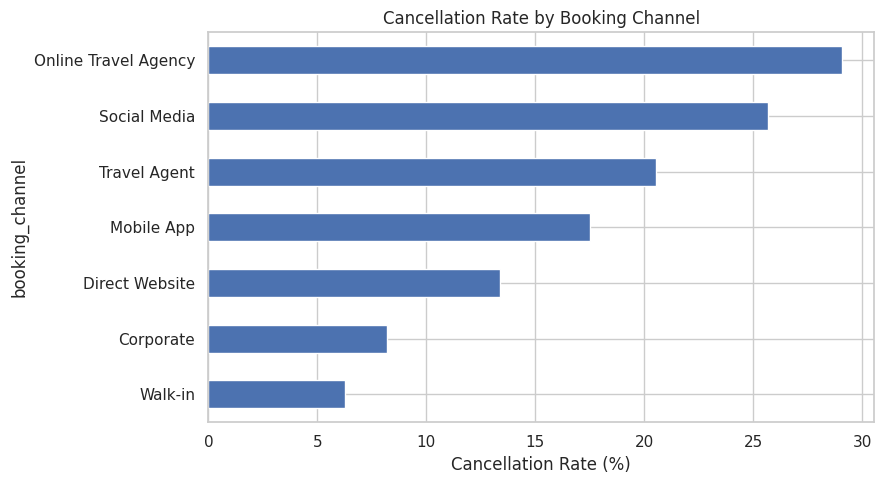

In [39]:
channel_col = "booking_channel"  # Change to actual column name

channel_analysis = (
    merged.groupby(channel_col, dropna=False)
    .agg(
        total_bookings=("cancellation_flag", "size"),
        cancelled=("cancellation_flag", "sum")
    )
)

channel_analysis["cancellation_rate"] = (
    channel_analysis["cancelled"] /
    channel_analysis["total_bookings"] * 100
)

display(channel_analysis.sort_values(
    "cancellation_rate", ascending=False
))

channel_analysis["cancellation_rate"].sort_values().plot(
    kind="barh", figsize=(9, 5)
)
plt.title("Cancellation Rate by Booking Channel")
plt.xlabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

,cancellation_flag
lead_time_group,
0-7 days,14.213198
8-30 days,14.393463
31-90 days,19.168357
90+ days,22.807018


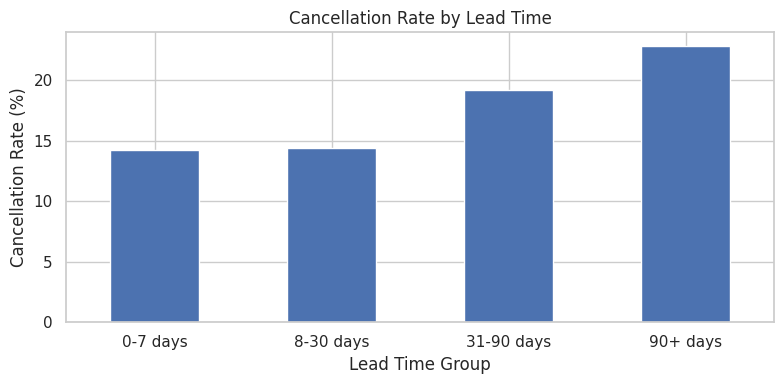

In [40]:
lead_analysis = (
    merged.dropna(subset=["lead_time_group"])
    .groupby("lead_time_group", observed=False)
    ["cancellation_flag"].mean() * 100
)

display(lead_analysis)

lead_analysis.plot(kind="bar", figsize=(8, 4))
plt.title("Cancellation Rate by Lead Time")
plt.xlabel("Lead Time Group")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,0
season,
Autumn,723
Monsoon,1388
Spring,360
Summer,690
Winter,810
NaN,29


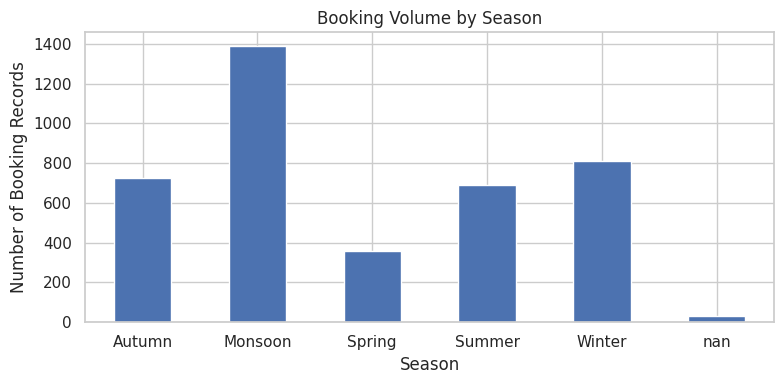

In [41]:
season_col = "season"  # Use the actual calendar column

season_bookings = merged.groupby(
    season_col, dropna=False
).size()

display(season_bookings)

season_bookings.plot(kind="bar", figsize=(8, 4))
plt.title("Booking Volume by Season")
plt.xlabel("Season")
plt.ylabel("Number of Booking Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,cancellation_flag
repeat_status,
New,17.947801
Repeat,15.544472


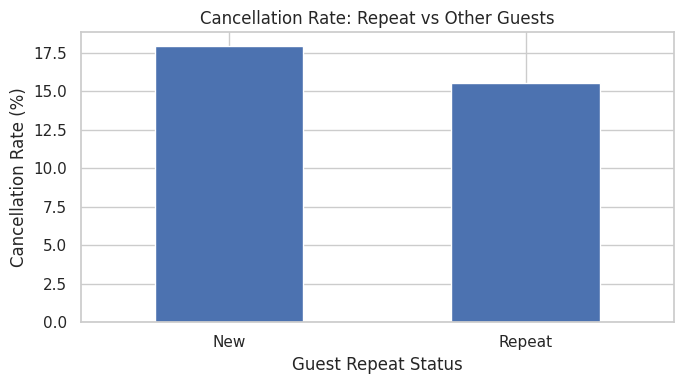

In [42]:
guest_col = "repeat_status"  # Replace if needed

guest_analysis = (
    merged.groupby(guest_col, dropna=False)
    ["cancellation_flag"].mean() * 100
)

display(guest_analysis)

guest_analysis.plot(kind="bar", figsize=(7, 4))
plt.title("Cancellation Rate: Repeat vs Other Guests")
plt.xlabel("Guest Repeat Status")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [43]:
room_analysis = merged.groupby(
    "room_type", dropna=False
).agg(
    bookings=("room_type", "size"),
    average_rate=("rate", "mean"),
    cancellation_rate=("cancellation_flag", "mean")
)

room_analysis["cancellation_rate"] *= 100

display(room_analysis.sort_values("bookings", ascending=False))

,bookings,average_rate,cancellation_rate
room_type,,,
standard,1444,2797.880194,16.759003
deluxe,1123,4316.462155,16.206589
family room,685,6315.886131,18.686131
suite,381,8435.538058,19.685039
executive,367,6640.572207,16.893733


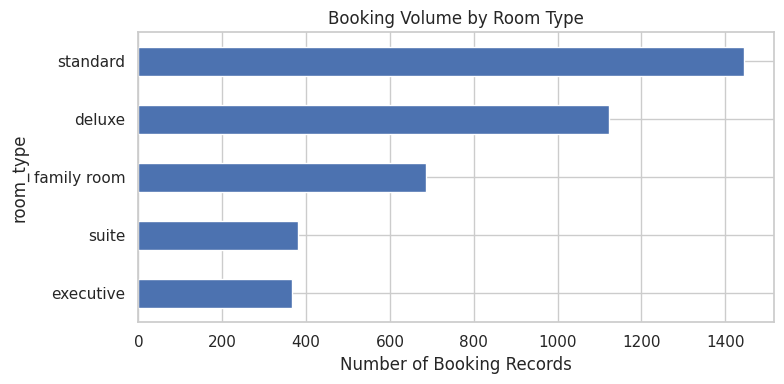

In [44]:
room_analysis["bookings"].sort_values().plot(
    kind="barh", figsize=(8, 4)
)
plt.title("Booking Volume by Room Type")
plt.xlabel("Number of Booking Records")
plt.tight_layout()
plt.show()

In [45]:
event_col = "event"  # Replace with actual calendar field

event_analysis = merged.groupby(
    event_col, dropna=False
).agg(
    bookings=("cancellation_flag", "size"),
    cancellation_rate=("cancellation_flag", "mean")
)

event_analysis["cancellation_rate"] *= 100
display(event_analysis)

,bookings,cancellation_rate
event,,
False,3600,17.055556
True,371,17.789757
NaN,29,31.034483


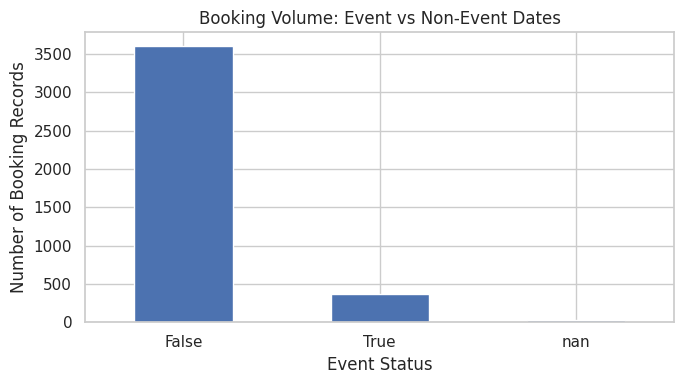

In [46]:
event_analysis["bookings"].plot(
    kind="bar", figsize=(7, 4)
)
plt.title("Booking Volume: Event vs Non-Event Dates")
plt.xlabel("Event Status")
plt.ylabel("Number of Booking Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

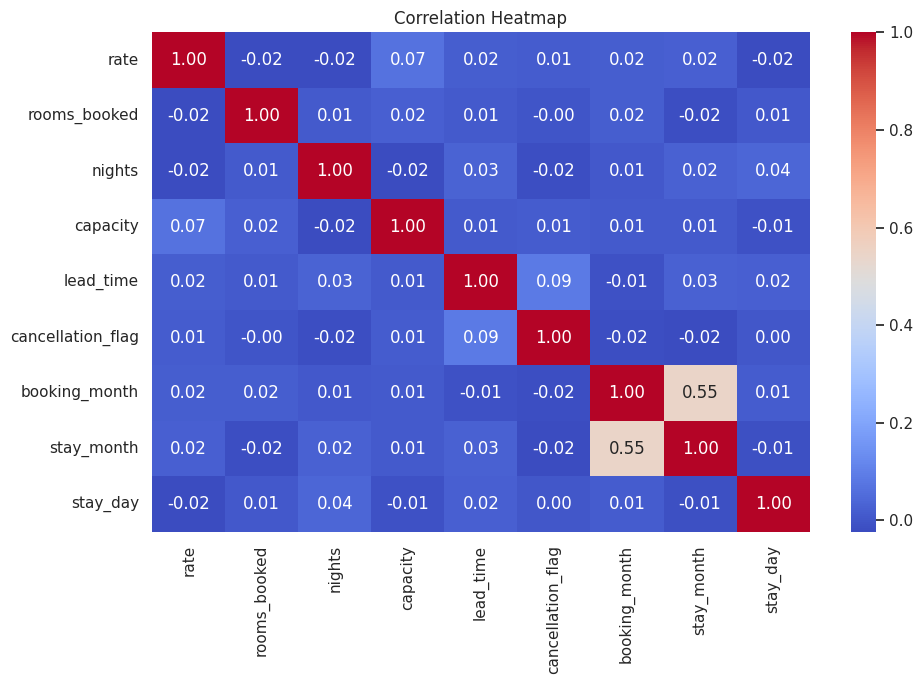

In [47]:
numeric_data = merged.select_dtypes(include=np.number)

correlation = numeric_data.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [48]:
encoded_data = merged.copy()

categorical_cols = encoded_data.select_dtypes(
    include=["object", "string", "category"]
).columns

for col in categorical_cols:
    encoded_data[col] = (
        encoded_data[col].astype("string").fillna("Unknown")
    )
    encoded_data[col] = LabelEncoder().fit_transform(
        encoded_data[col]
    )

In [49]:
target = "cancellation_flag"

exclude_cols = [
    target,
    "booking_id",
    "guest_id",
    "hotel_id",
    "channel_id"
]

X = encoded_data.drop(
    columns=[c for c in exclude_cols if c in encoded_data.columns],
    errors="ignore"
)

X = X.select_dtypes(include=np.number)

# Remove constant features
selector = VarianceThreshold(threshold=0)
X_selected = selector.fit_transform(X)

selected_features = X.columns[selector.get_support()]

print("Selected features:")
print(selected_features.tolist())

Selected features:
['room_type', 'rate', 'status', 'rooms_booked', 'nights', 'guest_type', 'origin', 'repeat_status', 'hotel_name', 'city', 'property_type', 'capacity', 'booking_channel', 'campaign', 'weekend', 'holiday', 'season', 'event', 'event_name', 'lead_time', 'booking_month', 'stay_month', 'stay_day', 'stay_weekday', 'lead_time_group']


In [50]:
merged.to_csv("staynest_cleaned_data.csv", index=False)

print("Cleaned dataset exported successfully.")

Cleaned dataset exported successfully.


In [61]:
selected_data = encoded_data[
    list(selected_features) + [target]
]

selected_data.to_csv(
    "staynest_selected_features.csv",
    index=False
)

In [62]:

from google.colab import files

# Download the cleaned dataset
merged.to_csv("staynest_cleaned_data.csv", index=False)
files.download("staynest_cleaned_data.csv")

# Download the selected features dataset
files.download("staynest_selected_features.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [55]:
%whos

Variable            Type                 Data/Info
--------------------------------------------------
IQR                 float64              2831.5
LabelEncoder        type                 <class 'sklearn.preproces<...>ing._label.LabelEncoder'>
Q1                  float64              2974.75
Q3                  float64              5806.25
StandardScaler      type                 <class 'sklearn.preproces<...>ng._data.StandardScaler'>
VarianceThreshold   ABCMeta              <class 'sklearn.feature_s<...>shold.VarianceThreshold'>
X                   DataFrame                  room_type    rate  <...>n[4000 rows x 25 columns]
X_selected          ndarray              4000x25: 100000 elems, type `float64`, 800000 bytes (781.25 kb)
bookings            DataFrame                 booking_id guest_id <...>n[4000 rows x 11 columns]
calendar            DataFrame                       date  weekend <...>\n[1096 rows x 6 columns]
categorical_cols    Index                Index(['booking_id', 'gu

In [63]:

print("Dataset shape:", merged.shape)
print("\nColumn names:")
print(merged.columns.tolist())

print("\nMissing values:")
print(merged.isnull().sum())

print("\nDuplicate rows:", merged.duplicated().sum())

display(merged.head())


Dataset shape: (4000, 34)

Column names:
['booking_id', 'guest_id', 'hotel_id', 'channel_id', 'booking_date', 'stay_date', 'room_type', 'rate', 'status', 'rooms_booked', 'nights', 'guest_type', 'origin', 'repeat_status', 'hotel_name', 'city', 'property_type', 'capacity', 'booking_channel', 'campaign', 'date', 'weekend', 'holiday', 'season', 'event', 'event_name', 'lead_time', 'cancellation_flag', 'booking_month', 'stay_month', 'stay_day', 'stay_weekday', 'is_weekend_calculated', 'lead_time_group']

Missing values:
booking_id                  0
guest_id                    0
hotel_id                    0
channel_id                  0
booking_date                0
stay_date                   0
room_type                   0
rate                        0
status                      0
rooms_booked                0
nights                      0
guest_type                  0
origin                      0
repeat_status               0
hotel_name                  0
city                        0


,booking_id,guest_id,hotel_id,channel_id,booking_date,stay_date,room_type,rate,status,rooms_booked,nights,guest_type,origin,repeat_status,hotel_name,city,property_type,capacity,booking_channel,campaign,date,weekend,holiday,season,event,event_name,lead_time,cancellation_flag,booking_month,stay_month,stay_day,stay_weekday,is_weekend_calculated,lead_time_group
0,B00001,G00005,H005,C05,2025-12-31,2026-03-20,family room,5662.0,cancelled,1,1,Leisure,Singapore,New,StayNest Coimbatore 05,Coimbatore,Business,54,Travel Agent,Corporate Deal,2026-03-20,False,False,Spring,False,NaN,79,1,12,3,20,Friday,False,31-90 days
1,B00002,G01152,H008,C03,2026-09-16,2026-10-02,family room,5359.0,confirmed,1,1,Leisure,Australia,New,StayNest Bengaluru 08,Bengaluru,Budget,76,Mobile App,Weekend Escape,2026-10-02,False,True,Autumn,False,NaN,16,0,9,10,2,Friday,False,8-30 days
2,B00003,G00571,H018,C01,2024-03-09,2024-05-21,deluxe,4217.0,confirmed,1,4,Family,Canada,New,StayNest Madurai 18,Madurai,Business,89,Direct Website,Festive Offer,2024-05-21,False,False,Summer,False,NaN,73,0,3,5,21,Tuesday,False,31-90 days
3,B00004,G01101,H006,C07,2026-05-16,2026-07-17,family room,4812.0,confirmed,1,2,Business,France,New,StayNest Madurai 06,Madurai,Boutique,122,Social Media,Early Bird,2026-07-17,False,False,Monsoon,False,NaN,62,0,5,7,17,Friday,False,31-90 days
4,B00005,G01178,H013,C02,2024-12-27,2025-01-14,standard,2364.0,cancelled,1,1,Leisure,France,New,StayNest Chennai 13,Chennai,Budget,113,Online Travel Agency,NaN,2025-01-14,False,False,Winter,True,Local Festival/Event,18,1,12,1,14,Tuesday,False,8-30 days


In [64]:

# 1. Cancellation by channel
channel_summary = merged.groupby(
    "booking_channel"
)["cancellation_flag"].agg(
    ["count", "sum", "mean"]
)

channel_summary["cancellation_rate_%"] = (
    channel_summary["mean"] * 100
)

display(channel_summary.sort_values(
    "cancellation_rate_%", ascending=False
))

# 2. Cancellation by lead-time group
display(
    merged.groupby(
        "lead_time_group", observed=False
    )["cancellation_flag"].mean().mul(100)
)

# 3. Booking volume by season
display(merged.groupby("season").size())

# 4. Repeat guest cancellation rate
display(
    merged.groupby("repeat_status")[
        "cancellation_flag"
    ].mean().mul(100)
)

# 5. Room-type performance
display(
    merged.groupby("room_type").agg(
        bookings=("booking_id", "count"),
        average_rate=("rate", "mean"),
        cancellation_rate=("cancellation_flag", "mean")
    )
)

# 6. Event impact
display(
    merged.groupby("event").agg(
        bookings=("booking_id", "count"),
        cancellation_rate=("cancellation_flag", "mean")
    )
)


,count,sum,mean,cancellation_rate_%
booking_channel,,,,
Online Travel Agency,581,169,0.290878,29.087780
Social Media,541,139,0.256932,25.693161
Travel Agent,575,118,0.205217,20.521739
Mobile App,577,101,0.175043,17.504333
Direct Website,606,81,0.133663,13.366337
Corporate,561,46,0.081996,8.199643
Walk-in,559,35,0.062612,6.261181


,cancellation_flag
lead_time_group,
0-7 days,14.213198
8-30 days,14.393463
31-90 days,19.168357
90+ days,22.807018


,0
season,
Autumn,723
Monsoon,1388
Spring,360
Summer,690
Winter,810


,cancellation_flag
repeat_status,
New,17.947801
Repeat,15.544472


,bookings,average_rate,cancellation_rate
room_type,,,
deluxe,1123,4316.462155,0.162066
executive,367,6640.572207,0.168937
family room,685,6315.886131,0.186861
standard,1444,2797.880194,0.167590
suite,381,8435.538058,0.196850


,bookings,cancellation_rate
event,,
False,3600,0.170556
True,371,0.177898
